# AeroMotion Dynamics | IA e análise de dados industriais

**Projeto Integrador Avançado** · Etapas 1 e 2 · Python 3.10+

Este notebook reproduz a inspeção, o saneamento, a engenharia temporal, a EDA e a avaliação multiclasse do CSV recebido. O dataset possui 12.000 leituras fornecidas, sem metadados de origem; a validação mede desempenho neste arquivo, não substitui validação de campo. Execute a partir da raiz do projeto. Os artefatos de modelo são gerados em `artifacts/`.

**Reprodutibilidade:** semente 42. **Alvo:** `tipo_falha` (0 normal, 1 desgaste de rolamento, 2 desbalanceamento de rotor, 3 cavitação/superaquecimento).

In [1]:
from pathlib import Path
import json
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# Jupyter may launch with the notebook folder as the working directory.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
from src.pipeline import SENSORS, PHYSICAL, TARGETS, load_and_engineer, train

CSV = Path('data/dados_sensores_aeromotion.csv')
OUT = Path('artifacts')
assert CSV.exists(), f'CSV não encontrado: {CSV.resolve()}'


## 1. Inspeção estrutural

Confirmamos tipos, chaves, duplicidades, distribuição temporal e ausência por equipamento. As amostras brutas são registradas a cada 10 minutos no eixo temporal global. Como as bancadas alternam registros no arquivo, o intervalo por equipamento pode ser maior que 10 minutos; por isso não se deve interpretar cada intervalo individual de equipamento como perda de pacote.

In [2]:
raw = pd.read_csv(CSV, parse_dates=['timestamp'])
display(raw.dtypes.to_frame('dtype'))
print('shape:', raw.shape, '| linhas duplicadas:', raw.duplicated().sum())
assert raw['timestamp'].notna().all()
global_steps = raw['timestamp'].drop_duplicates().sort_values().diff().dropna().dt.total_seconds()/60
display(global_steps.describe().to_frame('intervalo_global_min'))
missing_by_equipment = raw.groupby('id_equipamento')[SENSORS].apply(lambda g: g.isna().mean()*100)
display(missing_by_equipment.round(2).style.format('{:.2f}%'))
display(raw['tipo_falha'].value_counts().sort_index().rename(index=dict(enumerate(TARGETS))).to_frame('amostras'))


,dtype
timestamp,datetime64[us]
id_equipamento,str
modo_operacao,str
horas_operacao_acumuladas,float64
temperatura_mancal_c,float64
vibracao_rms_mms,float64
pressao_oleo_bar,float64
rotacao_rpm,float64
emissao_acustica_db,float64
corrente_eletrica_amp,float64


shape: (12000, 11) | linhas duplicadas: 0


,intervalo_global_min
count,11999.0
mean,10.0
std,0.0
min,10.0
25%,10.0
50%,10.0
75%,10.0
max,10.0


,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp
id_equipamento,,,,,,
TURB-101,2.79%,2.99%,2.76%,0.00%,4.01%,0.00%
TURB-102,3.51%,2.75%,2.65%,0.00%,4.44%,0.00%
TURB-103,3.78%,3.20%,2.87%,0.00%,4.05%,0.00%
TURB-104,3.57%,2.79%,2.66%,0.00%,3.64%,0.00%


,amostras
tipo_falha,
Normal,10560
Desgaste_Rolamento,600
Desbalanceamento_Rotor,480
Cavitacao_Superaquecimento,360


## 2. Saneamento e continuidade temporal

O dicionário informa faixas normais, não limites absolutos de falha. Usamos limites de plausibilidade deliberadamente amplos para remover interferências impossíveis (ex.: temperaturas próximas de 1000 °C, vibração negativa), preservando assinaturas legítimas de falha. Lacunas curtas internas são interpoladas no tempo por equipamento, sem extrapolar bordas. Para avaliação, a interpolação é feita separadamente dentro do bloco de treino e do bloco de teste para impedir vazamento entre períodos. Lacunas longas/restantes são imputadas pela mediana do treino no pipeline.

In [3]:
engineered, audit = load_and_engineer(CSV)
print(json.dumps(audit, indent=2, ensure_ascii=False, default=str))
clean = engineered.copy()
for _, idx in clean.groupby('id_equipamento', sort=False).groups.items():
    part = clean.loc[idx].sort_values('timestamp').set_index('timestamp')
    for col in SENSORS:
        part[col] = part[col].interpolate(method='time', limit=3, limit_area='inside')
    clean.loc[clean.index.intersection(idx), SENSORS] = part[SENSORS].to_numpy()


{
  "rows": 12000,
  "columns": [
    "timestamp",
    "id_equipamento",
    "modo_operacao",
    "horas_operacao_acumuladas",
    "temperatura_mancal_c",
    "vibracao_rms_mms",
    "pressao_oleo_bar",
    "rotacao_rpm",
    "emissao_acustica_db",
    "corrente_eletrica_amp",
    "tipo_falha"
  ],
  "missing_count": {
    "timestamp": 0,
    "id_equipamento": 0,
    "modo_operacao": 0,
    "horas_operacao_acumuladas": 0,
    "temperatura_mancal_c": 409,
    "vibracao_rms_mms": 352,
    "pressao_oleo_bar": 328,
    "rotacao_rpm": 0,
    "emissao_acustica_db": 484,
    "corrente_eletrica_amp": 0,
    "tipo_falha": 0
  },
  "missing_rate": {
    "timestamp": 0.0,
    "id_equipamento": 0.0,
    "modo_operacao": 0.0,
    "horas_operacao_acumuladas": 0.0,
    "temperatura_mancal_c": 0.034083333333333334,
    "vibracao_rms_mms": 0.029333333333333333,
    "pressao_oleo_bar": 0.027333333333333334,
    "rotacao_rpm": 0.0,
    "emissao_acustica_db": 0.04033333333333333,
    "corrente_eletrica_am

## 3. Features temporais

As janelas usam durações de tempo reais (1 h e 6 h), agrupadas por equipamento e calculadas antes da leitura atual (`shift(1)`). A cadência global do arquivo é 10 min, mas a alternância dos equipamentos torna irregular a distância entre leituras de uma mesma bancada. O desvio padrão fica ausente quando ainda não há pelo menos duas leituras históricas na janela. Severidade dinâmica é vibração RMS dividida por RPM.

In [4]:
feature_cols = [c for c in engineered if 'rolling_' in c or c == 'severidade_dinamica']
display(engineered[['timestamp','id_equipamento','temperatura_mancal_c','vibracao_rms_mms',*feature_cols]].head(12))


,timestamp,id_equipamento,temperatura_mancal_c,vibracao_rms_mms,vibracao_rms_mms_rolling_mean_1h,vibracao_rms_mms_rolling_std_1h,vibracao_rms_mms_rolling_mean_6h,vibracao_rms_mms_rolling_std_6h,temperatura_mancal_c_rolling_mean_1h,temperatura_mancal_c_rolling_std_1h,temperatura_mancal_c_rolling_mean_6h,temperatura_mancal_c_rolling_std_6h,severidade_dinamica
0,2026-01-01 00:20:00,TURB-101,57.83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-01-01 01:00:00,TURB-101,58.03,2.50,NaN,NaN,NaN,NaN,57.830000,NaN,57.830000,NaN,0.000855
2,2026-01-01 01:10:00,TURB-101,75.77,NaN,2.500000,NaN,2.500000,NaN,57.930000,0.141421,57.930000,0.141421,NaN
3,2026-01-01 02:30:00,TURB-101,64.11,13.47,NaN,NaN,2.500000,NaN,75.770000,NaN,63.876667,10.300414,0.004473
4,2026-01-01 03:30:00,TURB-101,49.55,1.28,13.470000,NaN,7.985000,7.756961,64.110000,NaN,63.935000,8.411062,0.000517
5,2026-01-01 05:00:00,TURB-101,99.67,3.18,1.280000,NaN,5.750000,6.713486,49.550000,NaN,61.058000,9.718288,0.001055
6,2026-01-01 05:10:00,TURB-101,62.51,14.40,2.230000,1.343503,5.107500,5.630141,74.610000,35.440192,67.493333,18.001033,0.004839
7,2026-01-01 05:50:00,TURB-101,69.86,4.56,6.286667,7.090284,6.966000,6.406558,70.576667,26.015513,66.781429,16.540213,0.001297
8,2026-01-01 06:10:00,TURB-101,52.56,1.68,9.480000,6.957931,6.565000,5.813776,66.185000,5.197235,67.166250,15.351895,0.000685
9,2026-01-01 06:20:00,TURB-101,73.42,11.10,6.880000,6.669813,5.867143,5.619225,61.643333,8.682502,65.543333,15.163289,0.003196


## 4. Análise exploratória multivariada

Correlação de Pearson é exploratória e não demonstra causalidade. Pairplot usa uma amostra estratificada para manter a execução leve. As comparações por regime dependem de sensores e falhas representados no CSV.

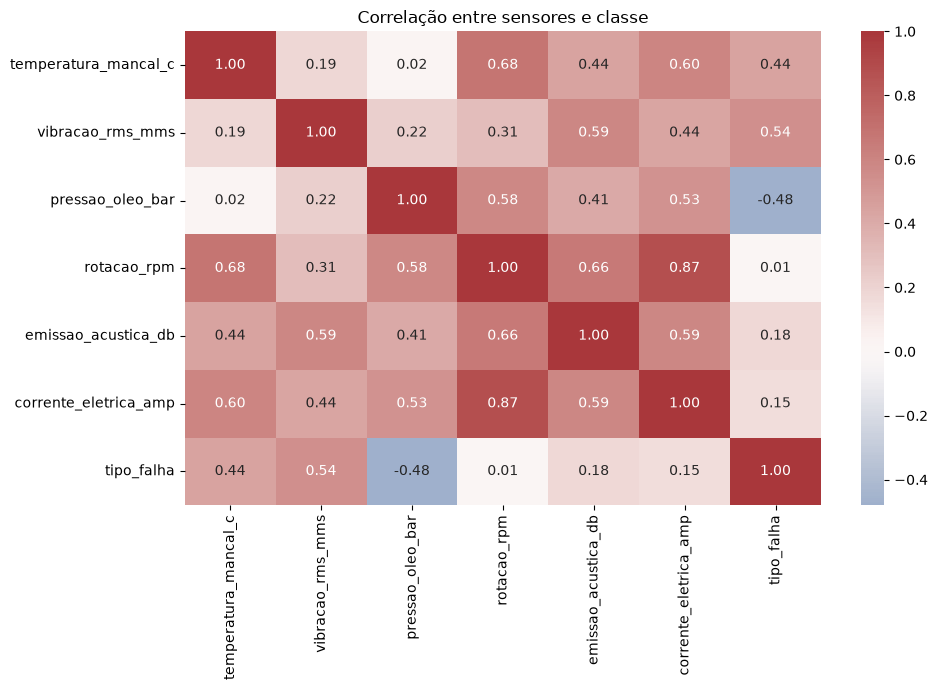

In [5]:
numeric = ['temperatura_mancal_c','vibracao_rms_mms','pressao_oleo_bar','rotacao_rpm','emissao_acustica_db','corrente_eletrica_amp','tipo_falha']
plt.figure(figsize=(10,7)); sns.heatmap(clean[numeric].corr(), cmap='vlag', center=0, annot=True, fmt='.2f'); plt.title('Correlação entre sensores e classe'); plt.tight_layout()
plt.show()


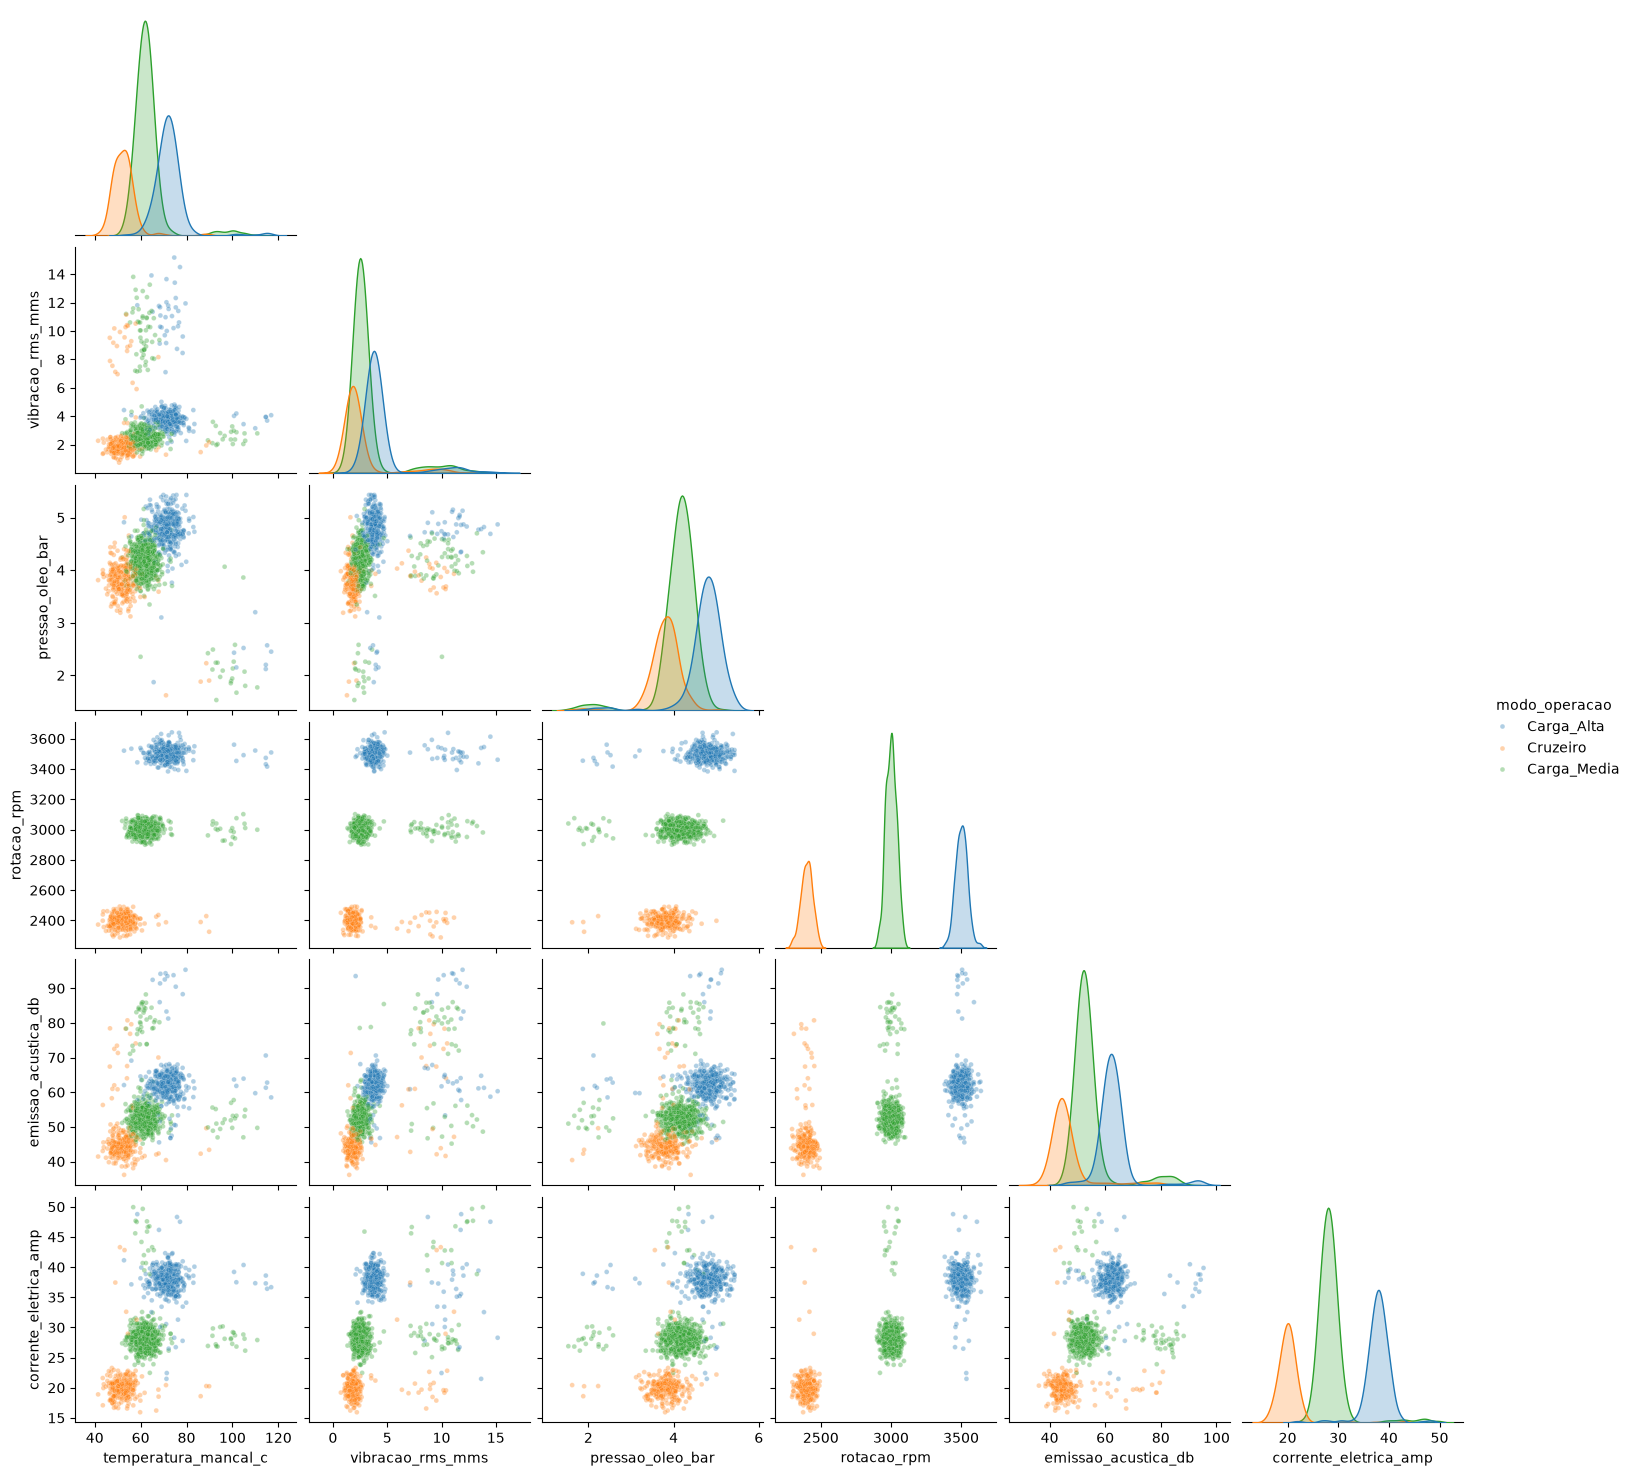

In [6]:
sns.pairplot(clean.sample(min(1200,len(clean)), random_state=42), vars=numeric[:6], hue='modo_operacao', corner=True, plot_kws={'alpha':.35,'s':12})
plt.show()


temperatura_mancal_c              vibracao_rms_mms               \
                              mean median   std             mean median   std   
modo_operacao                                                                   
Carga_Alta                   72.76  71.96  7.38             4.44   3.85  2.18   
Carga_Media                  62.99  62.11  7.00             3.18   2.56  2.19   
Cruzeiro                     53.41  52.22  7.40             2.43   1.88  2.06   

              pressao_oleo_bar              rotacao_rpm                 \
                          mean median   std        mean  median    std   
modo_operacao                                                            
Carga_Alta                4.71   4.78  0.49     3500.34  3500.6  40.21   
Carga_Media               4.14   4.19  0.45     3000.31  3000.6  39.56   
Cruzeiro                  3.74   3.80  0.48     2400.79  2400.6  39.75   

              emissao_acustica_db              corrente_eletrica_amp         \
                             mean median   std                  mean median   
modo_operacao                                                                 
Carga_Alta                  63.05  62.08  6.84                 37.80  37.96   
Carga_Media                 53.51  52.18  6.77                 28.61  28.05   
Cruzeiro                    45.66  44.29  6.65                 20.61  20.10   

                     
                std  
modo_operacao        
Carga_Alta     2.51  
Carga_Media    3.46  
Cruzeiro       3.40

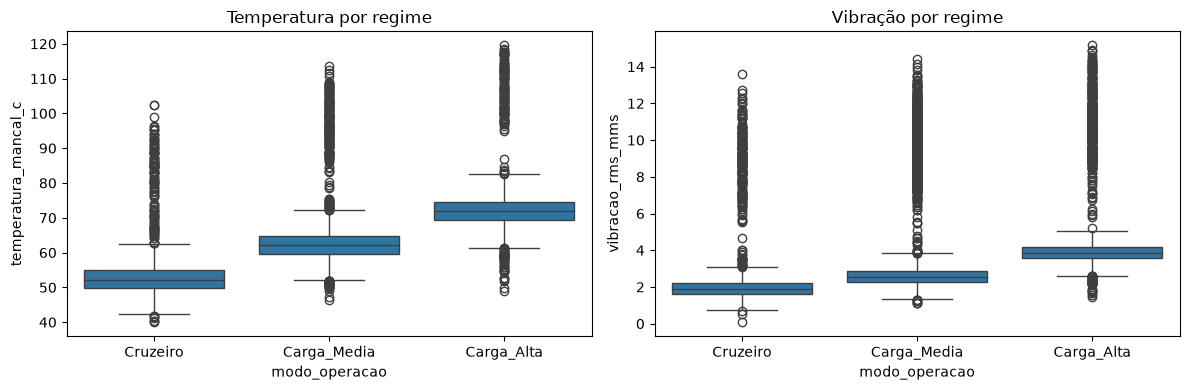

In [7]:
regime_summary = clean.groupby('modo_operacao')[numeric[:-1]].agg(['mean','median','std']).round(2)
display(regime_summary)
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=clean, x='modo_operacao', y='temperatura_mancal_c', ax=axes[0]); axes[0].set_title('Temperatura por regime')
sns.boxplot(data=clean, x='modo_operacao', y='vibracao_rms_mms', ax=axes[1]); axes[1].set_title('Vibração por regime')
plt.tight_layout(); plt.show()


## 5. Treino temporal, desbalanceamento e avaliação

O corte respeita a ordem temporal (70% treino, 30% teste). Pesos de classe substituem SMOTE, evitando criar vizinhos sintéticos que misturem períodos ou regimes. `RobustScaler` e imputadores são ajustados dentro do pipeline exclusivamente sobre o treino. Dois classificadores de árvores são comparados; o Random Forest é também ajustado por busca aleatória com validação temporal progressiva no treino. O bloco de teste permanece intocado até a avaliação final.

In [8]:
metrics = train(CSV, OUT)
pd.DataFrame({name:{k:v for k,v in values.items() if isinstance(v,(int,float))} for name,values in metrics['metrics'].items()}).T


,accuracy,precision_macro,precision_weighted,recall_macro,recall_weighted,f1_macro,f1_weighted,cv_recall_macro
random_forest_tuned,0.993056,0.986463,0.993054,0.964716,0.993056,0.975025,0.992934,0.987881
extra_trees_tuned,0.992222,0.990097,0.992192,0.956811,0.992222,0.972864,0.992082,0.979485



 random_forest_tuned | melhores parâmetros: {'model__n_estimators': 350, 'model__min_samples_leaf': 1, 'model__max_depth': None, 'model__class_weight': {0: 1, 1: 2, 2: 2, 3: 2}}
                            precision  recall  f1-score   support
Normal                          0.994   1.000     0.997  3159.000
Desgaste_Rolamento              0.994   0.902     0.946   183.000
Desbalanceamento_Rotor          0.967   0.967     0.967   151.000
Cavitacao_Superaquecimento      0.991   0.991     0.991   107.000
accuracy                        0.993   0.993     0.993     0.993
macro avg                       0.986   0.965     0.975  3600.000
weighted avg                    0.993   0.993     0.993  3600.000


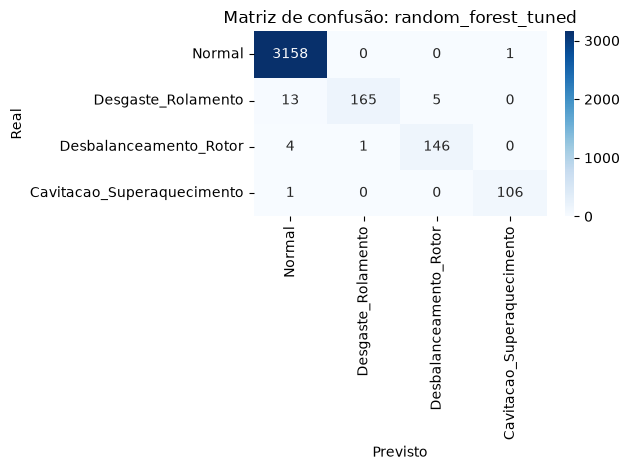


 extra_trees_tuned | melhores parâmetros: {'model__n_estimators': 250, 'model__min_samples_leaf': 1, 'model__max_depth': 28, 'model__class_weight': 'balanced'}
                            precision  recall  f1-score   support
Normal                          0.993   1.000     0.996  3159.000
Desgaste_Rolamento              0.988   0.902     0.943   183.000
Desbalanceamento_Rotor          0.980   0.954     0.966   151.000
Cavitacao_Superaquecimento      1.000   0.972     0.986   107.000
accuracy                        0.992   0.992     0.992     0.992
macro avg                       0.990   0.957     0.973  3600.000
weighted avg                    0.992   0.992     0.992  3600.000


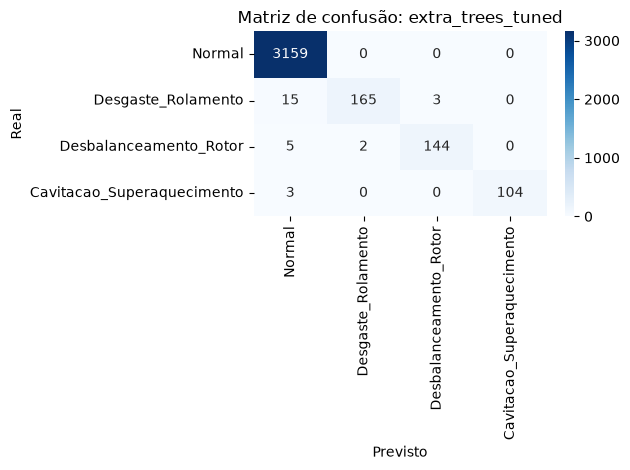

In [9]:
for name, score in metrics['metrics'].items():
    print('\n', name, '| melhores parâmetros:', score.get('best_params', 'padrão'))
    print(pd.DataFrame(score['classification_report']).T.round(3))
    cm = np.array(score['confusion_matrix'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=TARGETS, yticklabels=TARGETS)
    plt.xlabel('Previsto'); plt.ylabel('Real'); plt.title(f'Matriz de confusão: {name}'); plt.tight_layout(); plt.show()


## 6. Importância e anomalias não supervisionadas

O Random Forest fornece importância por redução de impureza, útil para triagem, mas enviesada em favor de variáveis com muitos pontos de corte. A leitura física deve ser confrontada com conhecimento de engenharia. Isolation Forest é ajustado apenas com exemplos normais do treino; seu limiar `contamination='auto'` requer calibração operacional antes de alarmar operadores.

,importância
numeric__severidade_dinamica,0.240980
numeric__vibracao_rms_mms,0.205160
numeric__emissao_acustica_db,0.167777
numeric__pressao_oleo_bar,0.133630
numeric__temperatura_mancal_c,0.122357
numeric__corrente_eletrica_amp,0.067463
numeric__rotacao_rpm,0.008136
numeric__temperatura_mancal_c_rolling_mean_1h,0.004805
numeric__vibracao_rms_mms_rolling_mean_6h,0.004712
numeric__temperatura_mancal_c_rolling_std_6h,0.004699


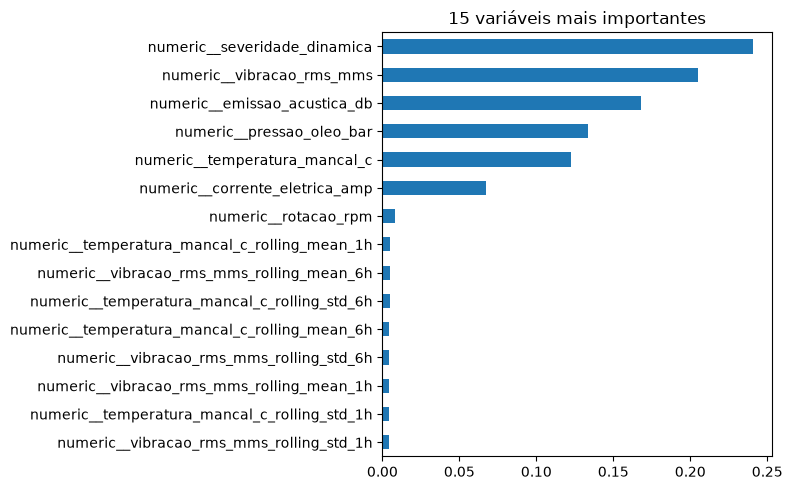

In [10]:
chosen = metrics['model']
import joblib
pipe = joblib.load(OUT/'model.joblib')
prep = pipe.named_steps['prep']; forest = pipe.named_steps['model']
names = prep.get_feature_names_out()
importance = pd.Series(forest.feature_importances_, index=names).sort_values(ascending=False).head(15)
display(importance.to_frame('importância'))
importance.sort_values().plot.barh(figsize=(8,5), title='15 variáveis mais importantes'); plt.tight_layout(); plt.show()


## 7. Conclusão e limites

Os resultados são elevados no arquivo fornecido, mas podem refletir assinaturas de falha muito separáveis e distribuição sintética. Exigir validação em novas campanhas, equipamentos, operadores e sensores; usar intervalos de confiança e custo de falso negativo; validar disponibilidade e sincronização temporal; monitorar drift; e manter aprovação humana para manutenção. A Etapa 3 entrega uma API com schemas, código OpenCV e Docker, mas a inspeção visual/ térmica precisa de imagens calibradas e rótulos reais para validação de desempenho.